In [1]:
# load model
import sys
sys.path.insert(0, "/home/go274/scratch_pi_skr2/go274/manual_MPRA_models/alphaMPRA")

import jax, jax.numpy as jnp, numpy as np
from alphagenome.models import dna_output
from alphagenome_research.model import dna_model
from alphagenome_ft import HeadConfig, HeadType, register_custom_head, load_checkpoint
from alphampra import EncoderMPRAHead

STAGE2 = "/home/go274/scratch_pi_skr2/go274/manual_MPRA_models/alphaMPRA/multihead_episomal_alphampra/checkpoints/episomal_alphampra_multihead/stage2"
BASE = "/home/go274/scratch_pi_skr2/go274/coda_data/claude_playground/alphagenome_weights/all_folds"
CELLS = ["K562", "HepG2", "SKNSH"]            # head order used in training
HEADS = [f"mpra_head_{c}" for c in CELLS]

# 1. register the three heads exactly as in training (same class and metadata)
for head in HEADS:
    register_custom_head(head, EncoderMPRAHead, HeadConfig(
        type=HeadType.GENOME_TRACKS, output_type=dna_output.OutputType.RNA_SEQ, num_tracks=1,
        metadata={"center_bp": 256, "pooling_type": "flatten", "nl_size": [512, 512], "do": 0.1, "activation": "relu"}))

# 2. load the folder
model = load_checkpoint(STAGE2, base_checkpoint_path=BASE, init_seq_len=600)

# 3. predict
strand_reindex = jax.device_put(model._metadata[dna_model.Organism.HOMO_SAPIENS].strand_reindexing,
                                model._device_context._device)

def predict(seqs):
    """list of 600bp strings -> (N, 3) predicted log2FC, columns K562, HepG2, SKNSH"""
    x = jnp.asarray(np.stack([model._one_hot_encoder.encode(s) for s in seqs]))   # (N, 600, 4)
    with model._device_context:
        out = model._predict(model._params, model._state, x, jnp.zeros(len(seqs), dtype=jnp.int32),
                             negative_strand_mask=jnp.zeros(len(seqs), dtype=bool),
                             strand_reindexing=strand_reindex, requested_outputs=tuple(dna_output.OutputType))
    return np.concatenate([np.asarray(out[h], dtype=np.float32).reshape(-1, 1) for h in HEADS], axis=1)


I0000 00:00:1790793332.540091 2836926 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790793335.836254 2836926 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Loading checkpoint from /nfs/roberts/scratch/pi_skr2/go274/manual_MPRA_models/alphaMPRA/multihead_episomal_alphampra/checkpoints/episomal_alphampra_multihead/stage2
  Custom heads: ['mpra_head_K562', 'mpra_head_HepG2', 'mpra_head_SKNSH']
  Model type: Minimal (encoder + heads only)
Loading pretrained AlphaGenome model...
  Using local checkpoint at: /home/go274/scratch_pi_skr2/go274/coda_data/claude_playground/alphagenome_weights/all_folds


/home/go274/.conda/envs/alphampra/lib/python3.11/site-packages/pyfaidx/__init__.py:596: UserWarning: for fsspec: HTTPFileSystem assuming index is current
  warnings.warn("for fsspec: %s assuming index is current" % type(self._fs).__name__)
/home/go274/.conda/envs/alphampra/lib/python3.11/site-packages/pyfaidx/__init__.py:596: UserWarning: for fsspec: HTTPFileSystem assuming index is current
  warnings.warn("for fsspec: %s assuming index is current" % type(self._fs).__name__)
E0930 14:36:03.221686 2836926 cuda_executor.cc:1182] [0] Failed to allocate device memory of 104.85GiB (112583507968 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0930 14:36:03.222544 2836926 cuda_executor.cc:1182] [0] Failed to allocate device memory of 94.37GiB (101325152256 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
E0930 14:36:03.223028 2836926 cuda_executor.cc:1182] [0] Failed to allocate device memory of 84.93GiB (91192631296 bytes): RESOURCE_EXHAUSTED: : CU

✓ Pretrained model loaded
Initializing heads: ['mpra_head_K562', 'mpra_head_HepG2', 'mpra_head_SKNSH']
Initializing parameters... (seq_len=600)
✓ Head parameters initialized
Merging pretrained backbone with heads...
✓ Parameters merged
✓ Model created successfully
  Total parameters: 463,049,352
  Heads: ['mpra_head_K562', 'mpra_head_HepG2', 'mpra_head_SKNSH']
Loading minimal model from checkpoint (encoder + custom heads only)...
  Creating model structure with encoder-only forward (init_seq_len=600bp)...
Loading pretrained AlphaGenome model...
  Using local checkpoint at: /home/go274/scratch_pi_skr2/go274/coda_data/claude_playground/alphagenome_weights/all_folds


/home/go274/.conda/envs/alphampra/lib/python3.11/site-packages/pyfaidx/__init__.py:596: UserWarning: for fsspec: HTTPFileSystem assuming index is current
  warnings.warn("for fsspec: %s assuming index is current" % type(self._fs).__name__)
/home/go274/.conda/envs/alphampra/lib/python3.11/site-packages/pyfaidx/__init__.py:596: UserWarning: for fsspec: HTTPFileSystem assuming index is current
  warnings.warn("for fsspec: %s assuming index is current" % type(self._fs).__name__)


✓ Pretrained model loaded
Initializing heads: ['mpra_head_K562', 'mpra_head_HepG2', 'mpra_head_SKNSH']
Initializing parameters... (seq_len=600)
✓ Head parameters initialized
Merging pretrained backbone with heads...
✓ Parameters merged
✓ Model created successfully
  Total parameters: 463,049,352
  Heads: ['mpra_head_K562', 'mpra_head_HepG2', 'mpra_head_SKNSH']
✓ Minimal model loaded (encoder + custom heads, encoder-only forward)
✓ Checkpoint loaded successfully
  Total parameters: 463,049,352


In [2]:
# predict the CODA synthetic sequences (MOESM14), flank-padded to 600bp and stderr-filtered
# by preprocess_synthetic_malinois.py
import pandas as pd
from scipy.stats import pearsonr

synth = pd.read_csv("/home/go274/scratch_pi_skr2/go274/manual_MPRA_models/alphaMPRA/coda_v_alphaMPRA/synthetic_seqs_predictions_padded600.txt", sep="\t")
seqs = synth["padded_sequence"].tolist()
assert all(len(s) == 600 for s in seqs), "expected 600bp padded sequences"
assert not synth[[f"{c}_l2fc" for c in CELLS]].isna().any().any(), "missing observed l2fc"
print(len(seqs), "synthetic sequences")   # 71,545

# predict in fixed-size chunks; the last chunk is padded with repeats so the model compiles once
CHUNK = 256
preds = []
for i in range(0, len(seqs), CHUNK):
    chunk = seqs[i:i + CHUNK]
    n = len(chunk)
    preds.append(predict(chunk + [chunk[-1]] * (CHUNK - n))[:n])
preds = np.concatenate(preds)        # (N, 3), columns K562, HepG2, SKNSH
assert preds.shape == (len(synth), 3)

# observed = <cell>_l2fc; the table's own <cell>_prediction columns are shown alongside for comparison
for i, c in enumerate(CELLS):
    synth[f"{c}_alphaMPRA"] = preds[:, i]
    r_alpha = pearsonr(synth[f"{c}_l2fc"], synth[f"{c}_alphaMPRA"])[0]
    r_table = pearsonr(synth[f"{c}_l2fc"], synth[f"{c}_prediction"])[0]
    print(f"{c}: alphaMPRA r = {r_alpha:.4f} | table's {c}_prediction r = {r_table:.4f}")

# Pearson r per sequence origin (natural vs each design method)
per_origin = pd.DataFrame({
    f"{c} {name}": synth.groupby("origin").apply(lambda g: pearsonr(g[f"{c}_l2fc"], g[col])[0])
    for c in CELLS for name, col in (("alphaMPRA", f"{c}_alphaMPRA"), ("table", f"{c}_prediction"))})
print(per_origin.round(3))

synth.to_csv("alphaMPRA_Malinois_synthetic_predictions.tsv", sep="\t", index=False)

71545 synthetic sequences
K562: alphaMPRA r = 0.9488 | table's K562_prediction r = 0.9085
HepG2: alphaMPRA r = 0.8969 | table's HepG2_prediction r = 0.7929
SKNSH: alphaMPRA r = 0.9391 | table's SKNSH_prediction r = 0.8845
                     K562 alphaMPRA  K562 table  HepG2 alphaMPRA  HepG2 table  \
origin                                                                          
AdaLead                       0.954       0.922            0.867        0.776   
DHS_natural                   0.931       0.865            0.903        0.799   
FastSeqProp                   0.954       0.928            0.889        0.808   
Malinois_natural              0.956       0.913            0.929        0.861   
Simulated_Annealing           0.947       0.911            0.911        0.811   
control                       0.930       0.910            0.854        0.831   

                     SKNSH alphaMPRA  SKNSH table  
origin                                             
AdaLead                  

/tmp/tmp.G9jGIY2ECv/ipykernel_2836926/496552629.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f"{c} {name}": synth.groupby("origin").apply(lambda g: pearsonr(g[f"{c}_l2fc"], g[col])[0])
/tmp/tmp.G9jGIY2ECv/ipykernel_2836926/496552629.py:31: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f"{c} {name}": synth.groupby("origin").apply(lambda g: pearsonr(g[f"{c}_l2fc"], g[col])[0])
/tmp/tmp.G9jGIY2ECv/ipykernel_2836

In [3]:
%matplotlib inline

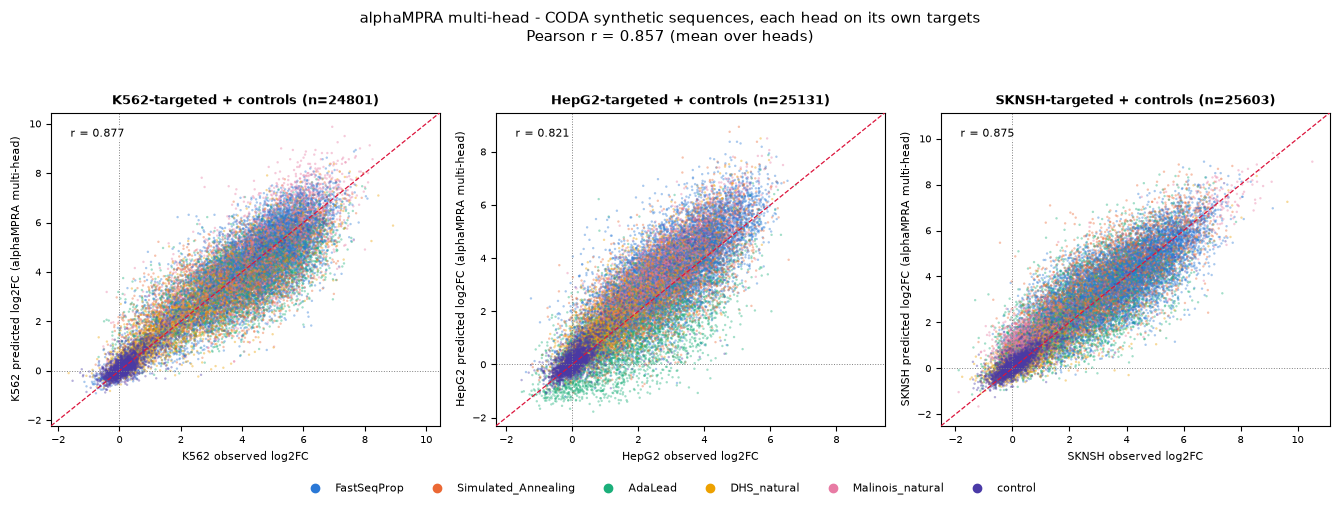

In [4]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# one color per origin, the same in every panel and figure
ORIGIN_COLORS = {"FastSeqProp": "#2a78d6", "Simulated_Annealing": "#eb6834", "AdaLead": "#1baf7a",
                 "DHS_natural": "#eda100", "Malinois_natural": "#e87ba4", "control": "#4a3aa7"}
assert set(synth["origin"]) == set(ORIGIN_COLORS), f"unexpected origins: {set(synth['origin']) - set(ORIGIN_COLORS)}"


def plot_by_origin(pred_suffix, model_name):
    """Observed <cell>_l2fc vs <cell><pred_suffix>, one panel per cell type, each panel only that cell
    type's targeted sequences plus the untargeted controls, points colored by origin."""
    rng = np.random.default_rng(0)   # same draw order for every model
    fig, axes = plt.subplots(1, len(CELLS), figsize=(4.5 * len(CELLS), 4.5), squeeze=False)
    rs = []
    for ax, c in zip(axes[0], CELLS):
        # this cell type's own targets plus the sequences with no target cell (controls)
        sub = synth[(synth["target_cell"] == c.lower()) | synth["target_cell"].isna()]
        x, y = sub[f"{c}_l2fc"].to_numpy(), sub[f"{c}{pred_suffix}"].to_numpy()

        # shared axis limits: min/max of both arrays + 5% margin
        vmin, vmax = min(x.min(), y.min()), max(x.max(), y.max())
        lim = (vmin - 0.05 * (vmax - vmin), vmax + 0.05 * (vmax - vmin))

        # all points in one shuffled draw so no origin is buried under another; controls on top
        is_ctrl = (sub["origin"] == "control").to_numpy()
        order = np.concatenate([rng.permutation(np.flatnonzero(~is_ctrl)), np.flatnonzero(is_ctrl)])
        colors = sub["origin"].map(ORIGIN_COLORS).to_numpy()
        ax.scatter(x[order], y[order], s=3, alpha=0.4, c=colors[order], linewidths=0, rasterized=True)

        ax.plot(lim, lim, color="crimson", linewidth=0.9, linestyle="--", zorder=3)   # identity line
        ax.axhline(0, color="gray", linewidth=0.7, linestyle=":", zorder=2)
        ax.axvline(0, color="gray", linewidth=0.7, linestyle=":", zorder=2)
        ax.set_xlim(lim)
        ax.set_ylim(lim)

        r = pearsonr(x, y)[0]
        rs.append(r)
        ax.text(0.05, 0.95, f"r = {r:.3f}", transform=ax.transAxes, fontsize=8, va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7))
        ax.set_title(f"{c}-targeted + controls (n={len(sub)})", fontsize=9, fontweight="bold")
        ax.set_xlabel(f"{c} observed log2FC", fontsize=8)
        ax.set_ylabel(f"{c} predicted log2FC ({model_name})", fontsize=8)
        ax.tick_params(labelsize=7)

    handles = [Line2D([], [], marker="o", linestyle="", markersize=6, color=col, label=o) for o, col in ORIGIN_COLORS.items()]
    fig.legend(handles=handles, loc="lower center", ncol=len(ORIGIN_COLORS), fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle(f"{model_name} - CODA synthetic sequences, each head on its own targets\n"
                 f"Pearson r = {np.mean(rs):.3f} (mean over heads)", fontsize=11, y=1.04)
    fig.tight_layout()
    return fig


fig = plot_by_origin("_alphaMPRA", "alphaMPRA multi-head")
#fig.savefig("alphaMPRA_synthetic_predictions_by_origin.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
fig.savefig("alphaMPRA_synthetic_predictions_by_origin_each_celltype_targeted.png", dpi=200, bbox_inches="tight")

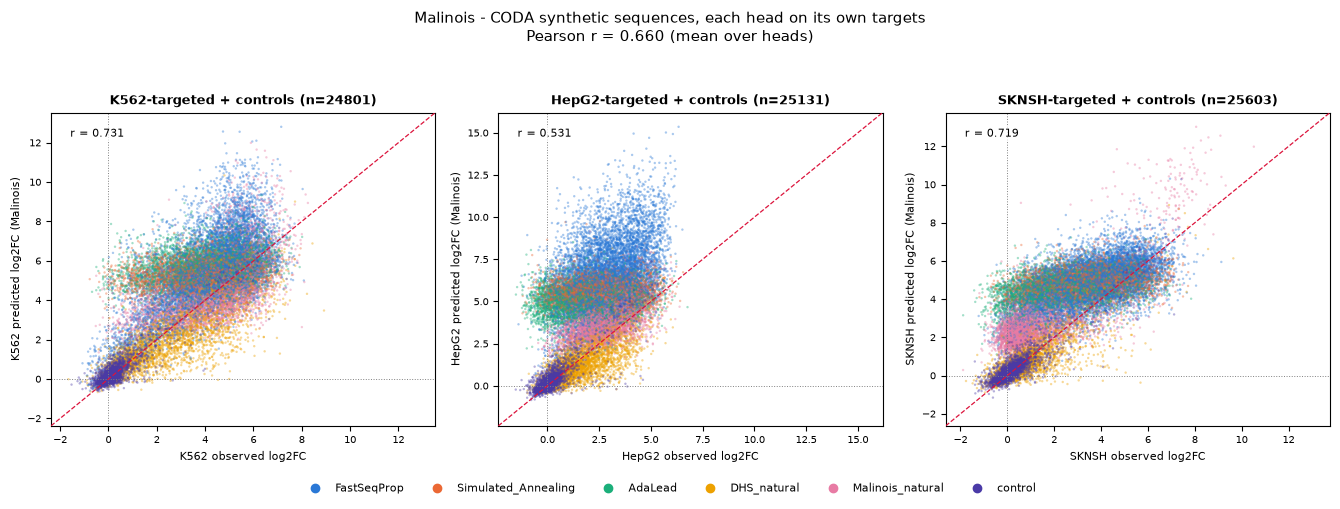

In [6]:
# same plot for the Malinois predictions already in the table (<cell>_prediction columns)
fig = plot_by_origin("_prediction", "Malinois")
#fig.savefig("malinois_synthetic_predictions_by_origin.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
fig.savefig("malinois_synthetic_predictions_by_origin_each_celltype_targeted.png", dpi=200, bbox_inches="tight")

In [8]:
TARGET_COLORS = {"k562": "#00a89d", "hepg2": "#fbaf42", "sknsh": "#ed1e29", "none (control)": "#dcdcdc"}


def plot_by_target(pred_suffix, model_name):
    """Observed <cell>_l2fc vs <cell><pred_suffix>, one panel per head, every sequence in every panel,
    points colored by the cell type the sequence was designed/selected for."""
    rng = np.random.default_rng(0)   # same draw order for every model
    target = synth["target_cell"].fillna("none (control)")
    assert set(target) == set(TARGET_COLORS), f"unexpected target cells: {set(target) - set(TARGET_COLORS)}"
    colors = target.map(TARGET_COLORS).to_numpy()
    # shuffled draw so no target cell type is buried under another; controls on top
    is_ctrl = (target == "none (control)").to_numpy()
    order = np.concatenate([rng.permutation(np.flatnonzero(~is_ctrl)), np.flatnonzero(is_ctrl)])

    fig, axes = plt.subplots(1, len(CELLS), figsize=(4.5 * len(CELLS), 4.5), squeeze=False)
    rs = []
    for ax, c in zip(axes[0], CELLS):
        x, y = synth[f"{c}_l2fc"].to_numpy(), synth[f"{c}{pred_suffix}"].to_numpy()

        # shared axis limits: min/max of both arrays + 5% margin
        vmin, vmax = min(x.min(), y.min()), max(x.max(), y.max())
        lim = (vmin - 0.05 * (vmax - vmin), vmax + 0.05 * (vmax - vmin))

        ax.scatter(x[order], y[order], s=3, alpha=0.4, c=colors[order], linewidths=0, rasterized=True)
        ax.plot(lim, lim, color="crimson", linewidth=0.9, linestyle="--", zorder=3)   # identity line
        ax.axhline(0, color="gray", linewidth=0.7, linestyle=":", zorder=2)
        ax.axvline(0, color="gray", linewidth=0.7, linestyle=":", zorder=2)
        ax.set_xlim(lim)
        ax.set_ylim(lim)

        r = pearsonr(x, y)[0]
        rs.append(r)
        ax.text(0.05, 0.95, f"r = {r:.3f}", transform=ax.transAxes, fontsize=8, va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7))
        ax.set_title(f"{c} head, all sequences (n={len(x)})", fontsize=9, fontweight="bold")
        ax.set_xlabel(f"{c} observed log2FC", fontsize=8)
        ax.set_ylabel(f"{c} predicted log2FC ({model_name})", fontsize=8)
        ax.tick_params(labelsize=7)

    handles = [Line2D([], [], marker="o", linestyle="", markersize=6, color=col, label=f"target: {t}")
               for t, col in TARGET_COLORS.items()]
    fig.legend(handles=handles, loc="lower center", ncol=len(TARGET_COLORS), fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle(f"{model_name} - CODA synthetic sequences, every head on all sequences\n"
                 f"Pearson r = {np.mean(rs):.3f} (mean over heads)", fontsize=11, y=1.04)
    fig.tight_layout()
    return fig


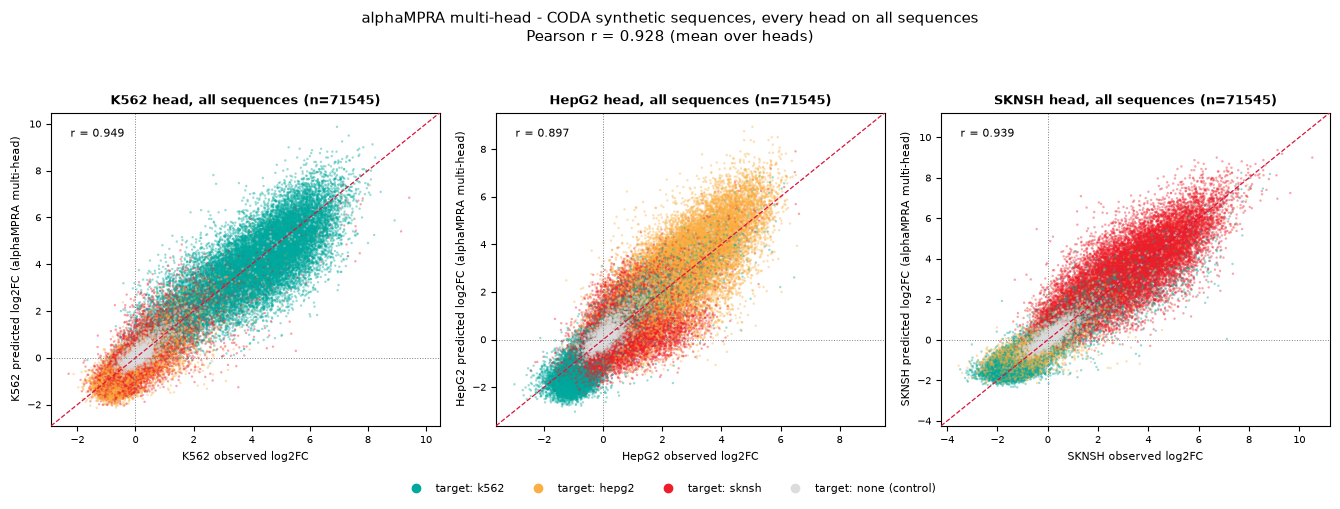

In [9]:
fig = plot_by_target("_alphaMPRA", "alphaMPRA multi-head")
plt.show()


In [10]:
fig.savefig("alphaMPRA_synthetic_predictions_all_celltypes.png", dpi=200, bbox_inches="tight")

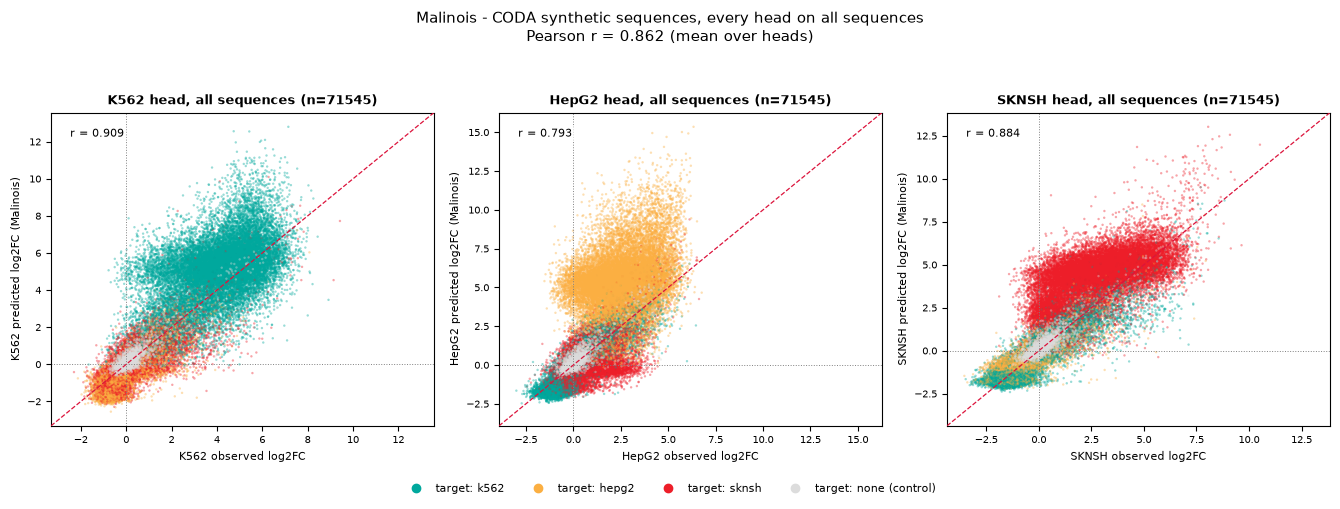

In [11]:
fig = plot_by_target("_prediction", "Malinois")
plt.show()

In [12]:
fig.savefig("malinois_synthetic_predictions_all_celltypes.png", dpi=200, bbox_inches="tight")

In [13]:
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

DENSITY_LEVELS = [0.167, 0.333, 0.5, 0.667, 0.833]   # fraction of points enclosed by each contour


def gap_and_top(values):
    """(N, 3) activities -> MinGap (top minus second, >= 0) and index of the top cell type"""
    s = np.sort(values, axis=1)
    return s[:, -1] - s[:, -2], values.argmax(axis=1)


def density_contours(ax, x, y, color, rng, max_points=5000):
    """Contours of a Gaussian KDE enclosing DENSITY_LEVELS of the points (highest-density regions)."""
    idx = rng.choice(len(x), size=min(max_points, len(x)), replace=False)   # KDE cost grows with n^2
    kde = gaussian_kde(np.vstack([x[idx], y[idx]]))
    # a contour enclosing fraction p of points sits at the (1 - p) quantile of the density at the points
    at_points = kde(np.vstack([x[idx], y[idx]]))
    thresholds = sorted(np.quantile(at_points, [1 - p for p in DENSITY_LEVELS]))
    xx, yy = np.meshgrid(np.linspace(*ax.get_xlim(), 150), np.linspace(*ax.get_ylim(), 150))
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contour(xx, yy, zz, levels=thresholds, colors=color, linewidths=0.9, zorder=3)


def plot_mingap(df, obs_suffix, pred_suffix, model_name, data_name):
    """Observed vs predicted MinGap per sequence; blue if the model's top cell type matches the observed one."""
    rng = np.random.default_rng(0)
    obs = df[[f"{c}{obs_suffix}" for c in CELLS]].to_numpy()    # (N, 3)
    pred = df[[f"{c}{pred_suffix}" for c in CELLS]].to_numpy()  # (N, 3)
    x, obs_top = gap_and_top(obs)
    y, pred_top = gap_and_top(pred)
    correct = obs_top == pred_top
    assert (x >= 0).all() and (y >= 0).all(), "MinGap must be non-negative"

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    lim = (-0.2, max(x.max(), y.max()) * 1.05)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    # (mask, point color, contour color, label); wrong drawn second so the smaller group stays visible
    groups = [(correct, "#2a78d6", "#0b2f6b", "top cell type correct"),
              (~correct, "#eb6834", "#8a3000", "top cell type wrong")]
    for mask, color, _, label in groups:
        ax.scatter(x[mask], y[mask], s=8, alpha=0.6, color=color, edgecolors="white", linewidths=0.3,
                   rasterized=True, label=f"{label} (n={mask.sum()}, {mask.mean():.1%})")
    for mask, _, line_color, _ in groups:
        density_contours(ax, x[mask], y[mask], line_color, rng)
    ax.plot(lim, lim, color="gray", linewidth=0.8, linestyle="--", zorder=2)   # identity line

    r = pearsonr(x, y)[0]
    ax.text(0.05, 0.95, f"Pearson r = {r:.3f}", transform=ax.transAxes, fontsize=9, va="top", ha="left",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
    ax.set_xlabel("observed MinGap (top - second log2FC)", fontsize=9)
    ax.set_ylabel(f"predicted MinGap ({model_name})", fontsize=9)
    ax.set_title(f"{model_name} - {data_name} (n={len(x)})", fontsize=10)
    ax.legend(loc="lower right", fontsize=8, markerscale=2, frameon=False)
    fig.tight_layout()
    return fig


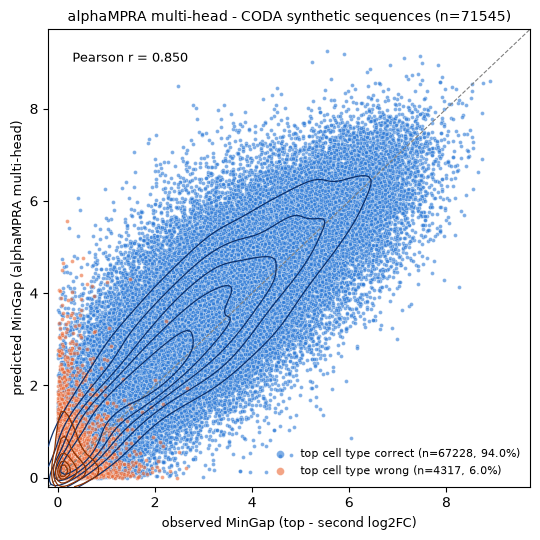

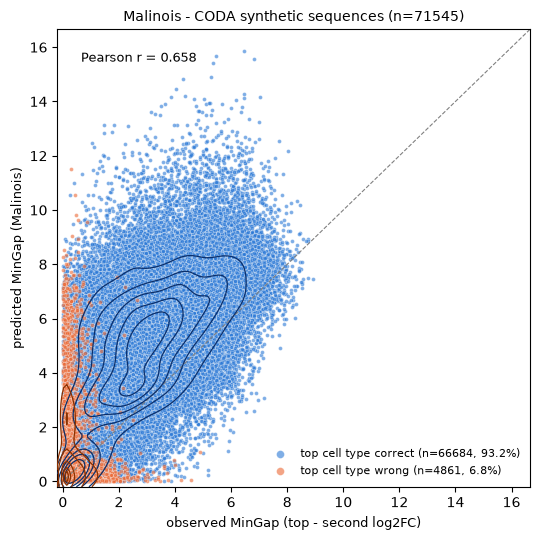

In [14]:
# synthetic sequences
fig = plot_mingap(synth, "_l2fc", "_alphaMPRA", "alphaMPRA multi-head", "CODA synthetic sequences")
plt.show()
fig.savefig("alphaMPRA_mingap_preds_synthetic.png", dpi=200, bbox_inches="tight")
fig = plot_mingap(synth, "_l2fc", "_prediction", "Malinois", "CODA synthetic sequences")
fig.savefig("malinois_mingap_preds_synthetic.png", dpi=200, bbox_inches="tight")
plt.show()

In [20]:
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

DENSITY_LEVELS = [0.167, 0.333, 0.5, 0.667, 0.833]   # fraction of points enclosed by each contour


def gap_and_top(values):
    """(N, 3) activities -> MinGap (top minus second, >= 0) and index of the top cell type"""
    s = np.sort(values, axis=1)
    return s[:, -1] - s[:, -2], values.argmax(axis=1)


def density_contours(ax, x, y, color, rng, max_points=5000):
    """Contours of a Gaussian KDE enclosing DENSITY_LEVELS of the points (highest-density regions)."""
    idx = rng.choice(len(x), size=min(max_points, len(x)), replace=False)   # KDE cost grows with n^2
    kde = gaussian_kde(np.vstack([x[idx], y[idx]]))
    # a contour enclosing fraction p of points sits at the (1 - p) quantile of the density at the points
    at_points = kde(np.vstack([x[idx], y[idx]]))
    thresholds = sorted(np.quantile(at_points, [1 - p for p in DENSITY_LEVELS]))
    xx, yy = np.meshgrid(np.linspace(*ax.get_xlim(), 150), np.linspace(*ax.get_ylim(), 150))
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contour(xx, yy, zz, levels=thresholds, colors=color, linewidths=0.9, zorder=3)


def plot_mingap(df, obs_suffix, pred_suffix, model_name, data_name):
    """Observed vs predicted MinGap per sequence; blue if the model's top cell type matches the observed one."""
    rng = np.random.default_rng(0)
    obs = df[[f"{c}{obs_suffix}" for c in CELLS]].to_numpy()    # (N, 3)
    pred = df[[f"{c}{pred_suffix}" for c in CELLS]].to_numpy()  # (N, 3)
    x, obs_top = gap_and_top(obs)
    y, pred_top = gap_and_top(pred)
    correct = obs_top == pred_top
    assert (x >= 0).all() and (y >= 0).all(), "MinGap must be non-negative"

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    lim = (-0.2, max(x.max(), y.max()) * 1.05)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    # (mask, point color, contour color, label, zorder); correct (blue) drawn above wrong (orange)
    groups = [(correct, "#2a78d6", "#0b2f6b", "top cell type correct", 1.5),
              (~correct, "#eb6834", "#8a3000", "top cell type wrong", 1)]
    for mask, color, _, label, z in groups:
        ax.scatter(x[mask], y[mask], s=8, alpha=0.6, color=color, edgecolors="white", linewidths=0.3,
                   rasterized=True, zorder=z, label=f"{label} (n={mask.sum()}, {mask.mean():.1%})")
    for mask, _, line_color, _, _ in groups:
        density_contours(ax, x[mask], y[mask], line_color, rng)
    ax.plot(lim, lim, color="gray", linewidth=0.8, linestyle="--", zorder=2)   # identity line

    r = pearsonr(x, y)[0]
    ax.text(0.05, 0.95, f"Pearson r = {r:.3f}", transform=ax.transAxes, fontsize=9, va="top", ha="left",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
    ax.set_xlabel("observed MinGap (top - second log2FC)", fontsize=9)
    ax.set_ylabel(f"predicted MinGap ({model_name})", fontsize=9)
    ax.set_title(f"{model_name} - {data_name} (n={len(x)})", fontsize=10)
    ax.legend(loc="upper right", fontsize=8, markerscale=2, frameon=True, edgecolor="black", framealpha=1)
    ax.get_legend().get_frame().set_linewidth(0.6)
    fig.tight_layout()
    return fig

# chr7 + chr13 rows of the boda tutorial's Malinois predictions table (observed <cell>_log2FC, Malinois <cell>_preds)
all_results = pd.read_csv("/home/go274/scratch_pi_skr2/go274/manual_MPRA_models/baseline_CODA/boda2/tutorials/MALINOIS_ALL_PREDICTIONS.tsv", sep="\t")
chr_filter = (all_results['chr'] == 7) | \
             (all_results['chr'] == 13) | \
             (all_results['chr'] == '7') | \
             (all_results['chr'] == '13')

test = all_results.loc[ chr_filter ]
#assert len(test) == 62582, f"expected 62,582 test rows, got {len(test)}"




/tmp/tmp.G9jGIY2ECv/ipykernel_2836926/644238076.py:61: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  all_results = pd.read_csv("/home/go274/scratch_pi_skr2/go274/manual_MPRA_models/baseline_CODA/boda2/tutorials/MALINOIS_ALL_PREDICTIONS.tsv", sep="\t")


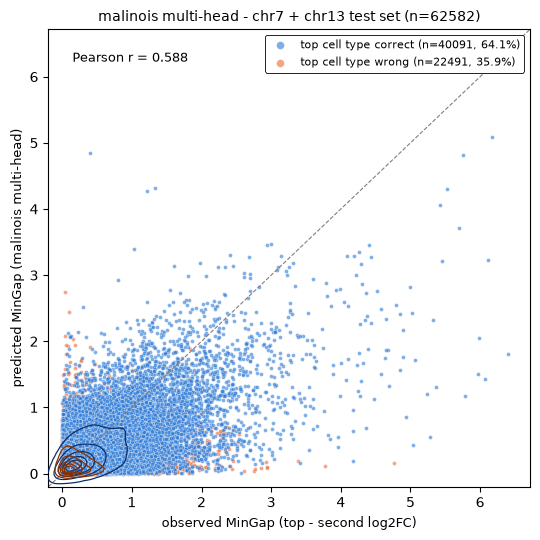

In [21]:
fig = plot_mingap(test, "_log2FC", "_preds", "malinois multi-head", "chr7 + chr13 test set")
fig.savefig("malinois_mingap_preds_natural.png", dpi=200, bbox_inches="tight")
plt.show()

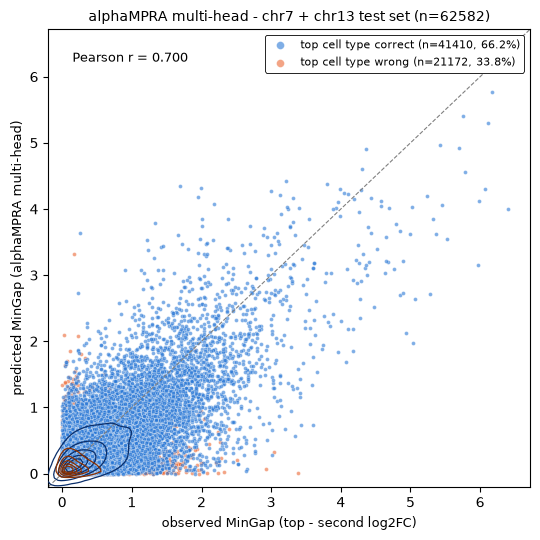

In [23]:
all_preds = pd.read_csv("/home/go274/scratch_pi_skr2/go274/manual_MPRA_models/alphaMPRA/ALPHAMPRA_ALL_PREDICTIONS.tsv", sep="\t")


test = all_preds[all_preds["split"] == "test"].reset_index(drop=True)
#assert len(test) == 62582, f"expected 62,582 test rows, got {len(test)}"

fig = plot_mingap(test, "_log2FC", "_predicted", "alphaMPRA multi-head", "chr7 + chr13 test set")
plt.show()

In [24]:
fig.savefig("alphaMPRA_mingap_preds_natural.png", dpi=200, bbox_inches="tight")


In [26]:
# variant predicitons

# for each cell type, find the real variant effect above 0.5 or below 0.5 log2FC wihtin each cell type
# 
import numpy as np
import pandas as pd

CELLS = ["K562", "HepG2", "SKNSH"]
DIFF_CUTOFF = 0.5

raw = pd.read_csv("/home/go274/scratch_pi_skr2/go274/coda_data/DATA-Table_S2__MPRA_dataset.txt", sep="\t", low_memory=False)

# test set: chr7 + chr13
test = raw[raw["chr"].astype(str).isin(["7", "13"])].copy()
test = test[test[["K562_lfcSE", "HepG2_lfcSE", "SKNSH_lfcSE"]].max(axis=1) < 1.0]
# some oligos carry several comma-separated IDs; give each ID its own row
test["ID"] = test["IDs"].str.split(",")
test = test.explode("ID").reset_index(drop=True)

# ID = chr:pos:ref:alt:allele:window[:extra]; allele is R (reference) or A (alternate).
# The pair key is the ID with the allele field removed (CRE oligos have 4-field IDs and no allele)
parts = test["ID"].str.split(":")
test = test[parts.str.len() >= 6].copy()
parts = test["ID"].str.split(":")
test["allele"] = parts.str[4]
test["pair_key"] = parts.apply(lambda p: ":".join(p[:4] + p[5:]))
test = test[test["allele"].isin(["R", "A"])]

cols = ["pair_key", "IDs", "sequence"] + [f"{c}_log2FC" for c in CELLS]
ref = test.loc[test["allele"] == "R", cols].drop_duplicates(["pair_key", "sequence"])
alt = test.loc[test["allele"] == "A", cols].drop_duplicates(["pair_key", "sequence"])
# a key still repeated here maps to two different oligos; drop it rather than guess which is right
amb_ref, amb_alt = ref["pair_key"].duplicated(keep=False), alt["pair_key"].duplicated(keep=False)
print(f"ambiguous keys dropped: ref {amb_ref.sum()}, alt {amb_alt.sum()}")
ref, alt = ref[~amb_ref], alt[~amb_alt]

# one row per ref/alt pair
pairs = ref.merge(alt, on="pair_key", suffixes=("_ref", "_alt"))
assert pairs["pair_key"].is_unique, "merge produced duplicate pairs"
assert len(pairs) <= min(len(ref), len(alt)), f"merge grew rows: {len(pairs)}"

# keep pairs whose oligos differ at exactly one position (single-nucleotide variants)
def n_mismatch(a, b):
    return np.inf if len(a) != len(b) else sum(x != y for x, y in zip(a, b))
pairs["n_diff_bases"] = [n_mismatch(a, b) for a, b in zip(pairs["sequence_ref"], pairs["sequence_alt"])]
snv = pairs[pairs["n_diff_bases"] == 1].copy()

# ref - alt activity per cell type
for c in CELLS:
    snv[f"{c}_diff"] = snv[f"{c}_log2FC_ref"] - snv[f"{c}_log2FC_alt"]

# keep pairs whose |ref - alt| exceeds the cutoff in at least one cell type
diff_cols = [f"{c}_diff" for c in CELLS]
strong = snv[(snv[diff_cols].abs() > DIFF_CUTOFF).any(axis=1)].reset_index(drop=True)

print(f"test oligo IDs: {len(test)} | ref/alt pairs: {len(pairs)} | single-nucleotide pairs: {len(snv)}")
print(f"pairs with |ref - alt| > {DIFF_CUTOFF} in any cell type: {len(strong)}")
for c in CELLS:
    print(f"  {c}: {(snv[f'{c}_diff'].abs() > DIFF_CUTOFF).sum()}")


ambiguous keys dropped: ref 0, alt 0
test oligo IDs: 62890 | ref/alt pairs: 30527 | single-nucleotide pairs: 28217
pairs with |ref - alt| > 0.5 in any cell type: 7307
  K562: 3589
  HepG2: 2508
  SKNSH: 4056


pairs: 7307 | with alphaMPRA predictions: 7307 | with Malinois: 7307 | both: 7307


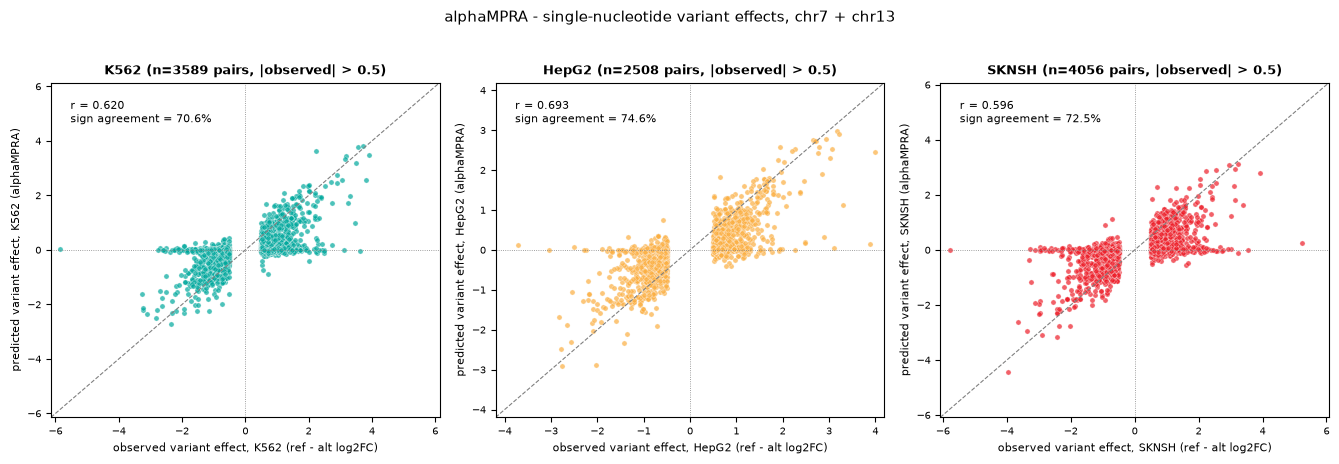

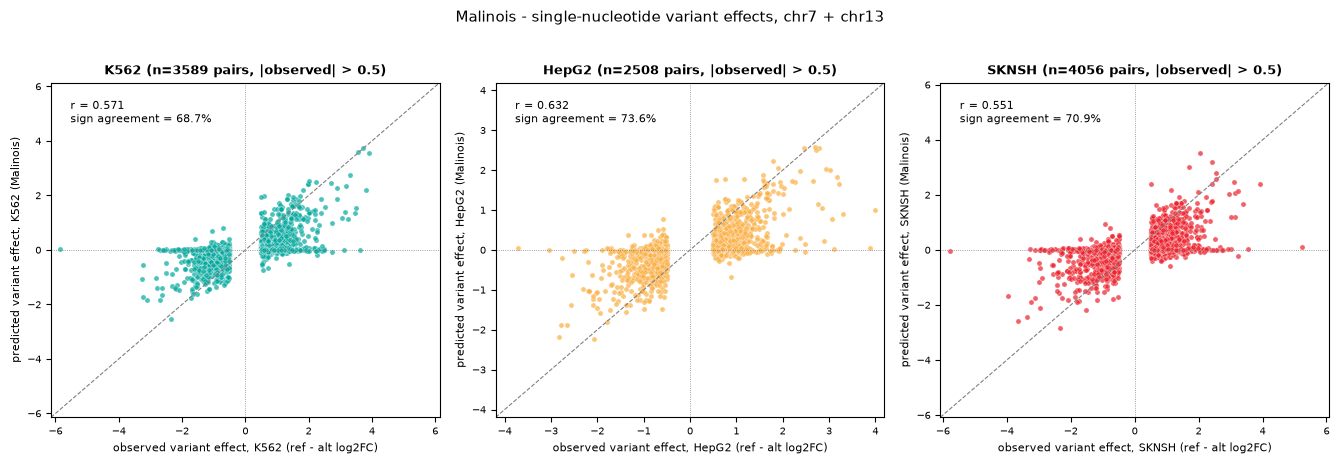

In [27]:
# observed vs predicted variant effect (ref - alt log2FC), one panel per cell type, for alphaMPRA and
# Malinois, using the saved predictions: all_preds (alphaMPRA, 600bp padded sequences, <cell>_predicted)
# and all_results (Malinois, raw oligo sequences, <cell>_preds)
CELL_COLORS = {"K562": "#00a89d", "HepG2": "#fbaf42", "SKNSH": "#ed1e29"}

# boda's MPRA flanks (boda2/boda/common/constants.py), 300bp each
MPRA_UPSTREAM = 'ACGAAAATGTTGGATGCTCATACTCGTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTACTAGTACGTCTCTCAAGGATAAGTAAGTAATATTAAGGTACGGGAGGTATTGGACAGGCCGCAATAAAATATCTTTATTTTCATTACATCTGTGTGTTGGTTTTTTGTGTGAATCGATAGTACTAACATACGCTCTCCATCAAAACAAAACGAAACAAAACAAACTAGCAAAATAGGCTGTCCCCAGTGCAAGTGCAGGTGCCAGAACATTTCTCTGGCCTAACTGGCCGCTTGACG'
MPRA_DOWNSTREAM = 'CACTGCGGCTCCTGCGATCTAACTGGCCGGTACCTGAGCTCGCTAGCCTCGAGGATATCAAGATCTGGCCTCGGCGGCCAAGCTTAGACACTAGAGGGTATATAATGGAAGCTCGACTTCCAGCTTGGCAATCCGGTACTGTTGGTAAAGCCACCATGGTGAGCAAGGGCGAGGAGCTGTTCACCGGGGTGGTGCCCATCCTGGTCGAGCTGGACGGCGACGTAAACGGCCACAAGTTCAGCGTGTCCGGCGAGGGCGAGGGCGATGCCACCTACGGCAAGCTGACCCTGAAGTTCATCT'

def pad_to_600(seq, L=600):
    """Same as boda.common.utils.row_pad_sequence: flanks split around the oligo, extra base downstream."""
    n = L - len(seq)
    up = MPRA_UPSTREAM[-n // 2 + n % 2:] if -n // 2 + n % 2 < 0 else ""
    return up + seq + MPRA_DOWNSTREAM[:n // 2 + n % 2]

# sequence -> (3,) predictions, one entry per unique sequence
alpha_lookup = all_preds.drop_duplicates("sequence").set_index("sequence")[[f"{c}_predicted" for c in CELLS]]
mal_lookup = all_results.drop_duplicates("sequence").set_index("sequence")[[f"{c}_preds" for c in CELLS]]

var = strong.copy()
var["padded_ref"] = var["sequence_ref"].map(pad_to_600)
var["padded_alt"] = var["sequence_alt"].map(pad_to_600)

# keep pairs where both alleles have predictions from both models, so both plots use the same pairs
has_alpha = var["padded_ref"].isin(alpha_lookup.index) & var["padded_alt"].isin(alpha_lookup.index)
has_mal = var["sequence_ref"].isin(mal_lookup.index) & var["sequence_alt"].isin(mal_lookup.index)
print(f"pairs: {len(var)} | with alphaMPRA predictions: {has_alpha.sum()} | with Malinois: {has_mal.sum()} | both: {(has_alpha & has_mal).sum()}")
var = var[has_alpha & has_mal].reset_index(drop=True)

# predicted ref - alt for each model
a_ref = alpha_lookup.loc[var["padded_ref"]].to_numpy()
a_alt = alpha_lookup.loc[var["padded_alt"]].to_numpy()
m_ref = mal_lookup.loc[var["sequence_ref"]].to_numpy()
m_alt = mal_lookup.loc[var["sequence_alt"]].to_numpy()
assert a_ref.shape == m_ref.shape == (len(var), 3)
for i, c in enumerate(CELLS):
    var[f"{c}_pred_diff_alphaMPRA"] = a_ref[:, i] - a_alt[:, i]
    var[f"{c}_pred_diff_Malinois"] = m_ref[:, i] - m_alt[:, i]


def plot_variant_effects(model):
    """Observed vs <model>-predicted ref - alt per cell type, each panel only pairs with |observed| > DIFF_CUTOFF there."""
    fig, axes = plt.subplots(1, len(CELLS), figsize=(4.5 * len(CELLS), 4.5), squeeze=False)
    for ax, c in zip(axes[0], CELLS):
        sub = var[var[f"{c}_diff"].abs() > DIFF_CUTOFF]     # pairs with a variant effect in this cell type
        x, y = sub[f"{c}_diff"].to_numpy(), sub[f"{c}_pred_diff_{model}"].to_numpy()

        lim_abs = max(np.abs(x).max(), np.abs(y).max()) * 1.05
        lim = (-lim_abs, lim_abs)
        ax.scatter(x, y, s=14, alpha=0.7, color=CELL_COLORS[c], edgecolors="white", linewidths=0.3, rasterized=True)
        ax.plot(lim, lim, color="gray", linewidth=0.8, linestyle="--", zorder=2)   # identity line
        ax.axhline(0, color="gray", linewidth=0.6, linestyle=":", zorder=1)
        ax.axvline(0, color="gray", linewidth=0.6, linestyle=":", zorder=1)
        ax.set_xlim(lim)
        ax.set_ylim(lim)

        r = pearsonr(x, y)[0]
        same_sign = (np.sign(x) == np.sign(y)).mean()        # predicted direction matches observed
        ax.text(0.05, 0.95, f"r = {r:.3f}\nsign agreement = {same_sign:.1%}", transform=ax.transAxes,
                fontsize=8, va="top", ha="left", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
        ax.set_title(f"{c} (n={len(sub)} pairs, |observed| > {DIFF_CUTOFF})", fontsize=9, fontweight="bold")
        ax.set_xlabel(f"observed variant effect, {c} (ref - alt log2FC)", fontsize=8)
        ax.set_ylabel(f"predicted variant effect, {c} ({model})", fontsize=8)
        ax.tick_params(labelsize=7)

    fig.suptitle(f"{model} - single-nucleotide variant effects, chr7 + chr13", fontsize=11, y=1.02)
    fig.tight_layout()
    return fig


fig = plot_variant_effects("alphaMPRA")
plt.show()
fig = plot_variant_effects("Malinois")
plt.show()
